# Pair B, Phase I. How do the models behave?


**Story: what does each model match on, and how stable are its neighbours?**

Both models return the 10 most similar patients for a diabetes stay. Pair A showed *what* happens on average: both models reach the same accuracy but react to different edits. This notebook asks *for whom* and *under which inputs*, per stay.


| RQ | Question | Sections |
|---|---|---|
| RQ3  Bias | Are neighbours chosen by demographics (sex, race, age) rather than clinical state? | 1 |
| RQ4  Sensitivity | How sensitive are the neighbours to editing one field (sex, age, HbA1c)? | 2–5 |
| RQ1 (rare-pathway part) / RQ5  Rare pathways | Why are the rare pathways never predicted? (extends optional RQ5 from Eye/Neuro to Kidney) | 6 |

RQ1 (overall errors, where in patient space it fails) and RQ2 (confidence) are answered by Pair A. We add the rare-pathway part of RQ1 (section 6) and, for RQ2, that the distance gap signals stability, not correctness (section 3).

In [66]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("../../shared/data")
cohort = pd.read_parquet(DATA_DIR / "cohort_encounters.parquet")
retrieval = pd.read_parquet(DATA_DIR / "retrieval_results.parquet")
flips = pd.read_parquet(DATA_DIR / "counterfactual_flips.parquet")
df = (cohort
      .merge(retrieval.drop(columns=["patient_nbr", "true_next_pathway"]), on="encounter_id", validate="one_to_one")
      .merge(flips.drop(columns=["patient_nbr"]), on="encounter_id", validate="one_to_one"))


pos = pd.Index(df["encounter_id"])
NB = {m: pos.get_indexer(np.concatenate(df[f"{m}_neighbors"].to_numpy())).reshape(len(df), -1)
      for m in ["model_a", "model_b", "random"]}
assert all((v >= 0).all() for v in NB.values())

MODELS = {"model_a": "Model A (features)", "model_b": "Model B (Bio_ClinicalBERT)"}
COL = {"model_a": "#1F5FAE", "model_b": "#B8561B", "random": "#8A93A6"}
EDITS = {"sex_swap": "Sex swap", "age_shift": "Age +20 years", "hba1c_elevation": "HbA1c to >8"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
print(f"{len(df):,} stays, {df.patient_nbr.nunique():,} patients")

30,248 stays, 16,773 patients


## 1. RQ3  Are neighbours chosen by demographics rather than clinical state?

The 15 input fields fall into three groups: **demographic** (sex, race, age), **clinical** (HbA1c, glucose, insulin, medication change, number of medications, lab procedures, diagnoses, days in hospital) and **administrative** (admission type and source, specialty, payer).

For each field: the share of the 10 neighbours with the same value as the patient, minus the same share for 10 random patients. 

Lift = how much more often a model's neighbours share a field with the patient than random patients.

In [67]:
GROUPS = {
    "demographic": ["gender", "race", "age_mid"],
    "clinical": ["A1Cresult", "max_glu_serum", "insulin", "change", "diabetesMed",
                 "num_medications", "num_lab_procedures", "number_diagnoses", "time_in_hospital"],
    "administrative": ["admission_type", "admission_source", "medical_specialty", "payer_code"],
    "outcome": ["true_next_pathway"],
}
numeric = ["age_mid", "time_in_hospital", "num_lab_procedures", "num_medications", "number_diagnoses"]
codes = {f: (pd.qcut(df[f].rank(method="first"), 4, labels=False).to_numpy() if f in numeric
             else pd.factorize(df[f])[0]) for g in GROUPS.values() for f in g}

rows = []
for group, fields in GROUPS.items():
    for f in fields:
        v = codes[f]
        share = {m: (v[NB[m]] == v[:, None]).mean() for m in NB}
        rows.append({"group": group, "field": f, **share,
                     "lift_A": share["model_a"] - share["random"], "lift_B": share["model_b"] - share["random"]})
profile = pd.DataFrame(rows)
profile.round(3)

,group,field,model_a,model_b,random,lift_A,lift_B
0,demographic,gender,0.947,0.709,0.505,0.442,0.204
1,demographic,race,0.656,0.659,0.599,0.056,0.060
2,demographic,age_mid,0.577,0.561,0.250,0.327,0.311
3,clinical,A1Cresult,0.918,0.925,0.727,0.191,0.197
4,clinical,max_glu_serum,0.981,0.976,0.882,0.099,0.094
5,clinical,insulin,0.920,0.837,0.308,0.612,0.529
6,clinical,change,0.973,0.933,0.500,0.473,0.433
7,clinical,diabetesMed,0.985,0.992,0.679,0.306,0.313
8,clinical,num_medications,0.566,0.418,0.249,0.317,0.169
9,clinical,num_lab_procedures,0.612,0.404,0.250,0.362,0.155


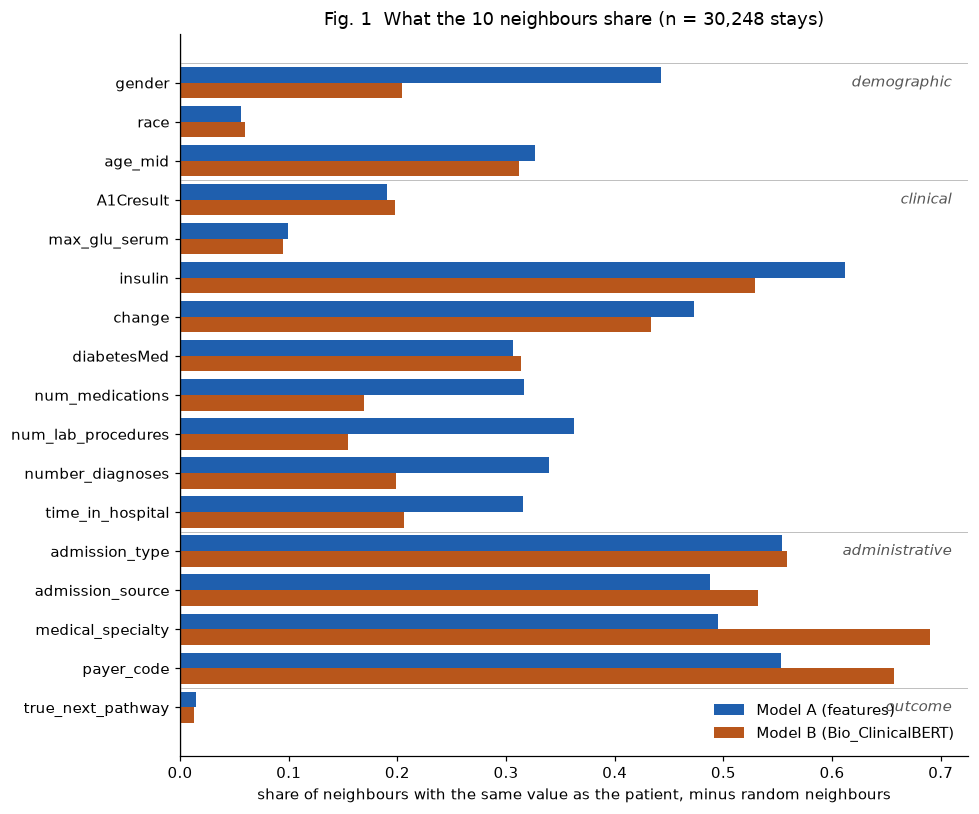

In [68]:
fig, ax = plt.subplots(figsize=(9, 7.5))
y = np.arange(len(profile))[::-1]
ax.barh(y + 0.2, profile["lift_A"], height=0.4, color=COL["model_a"], label=MODELS["model_a"])
ax.barh(y - 0.2, profile["lift_B"], height=0.4, color=COL["model_b"], label=MODELS["model_b"])
ax.set_yticks(y, profile["field"])
ax.axvline(0, color="#333", lw=0.8)


start = 0
for group, fields in GROUPS.items():
    top = len(profile) - start - 0.5
    ax.axhline(top, color="#BBB", lw=0.6)
    ax.text(0.71, top - 0.6, group, fontsize=10, color="#555", ha="right", style="italic")
    start += len(fields)
ax.set_xlabel("share of neighbours with the same value as the patient, minus random neighbours")
ax.set_title("Fig. 1  What the 10 neighbours share (n = 30,248 stays)")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout()

**Fig. 1.** Model A matches strongly on sex (+0.44: 95% of neighbours share the patient's sex, random 50%), more strongly than most clinical fields; only insulin (+0.61) and medication change (+0.47) are matched more strongly. Model B matches on sex much less (+0.20). Race plays almost no role for either model (+0.06). Age is matched similarly by both (+0.33 / +0.31). Both models match administrative fields strongly, but for Model B they are the strongest of all: specialty (+0.69), payer (+0.66), admission type and source (+0.56 / +0.53). The outcome row shows that the neighbours of both models share the next pathway barely more often than random patients (+0.01).

### 1b. How close are the neighbours in the numeric fields?

Mean absolute difference between the patient and its 10 neighbours, per numeric field.

,model_a,model_b,random
num_medications,3.33,5.97,8.33
num_lab_procedures,7.76,15.21,21.71
time_in_hospital,1.19,2.22,3.22
number_diagnoses,0.49,1.14,1.84


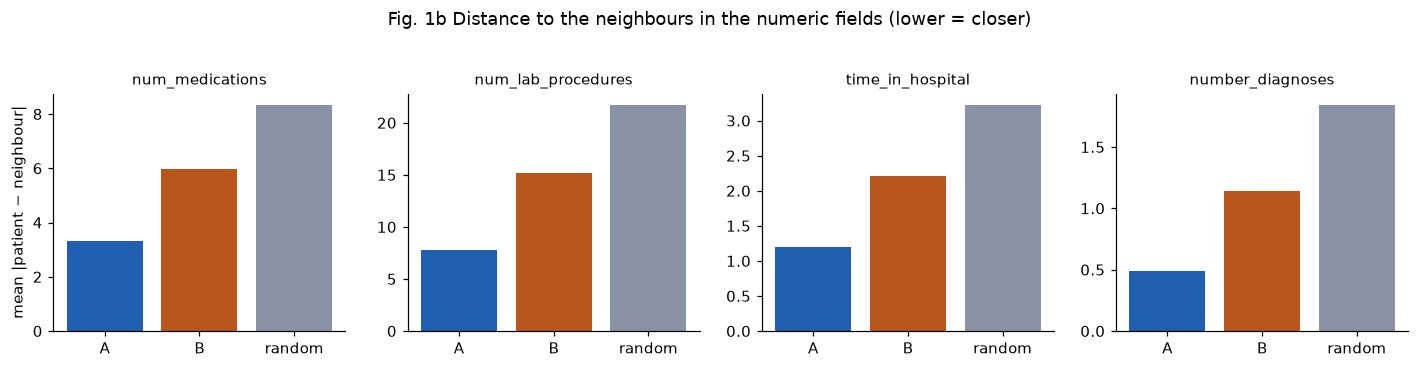

In [69]:
num_gap = pd.DataFrame({m: {f: np.abs(df[f].to_numpy()[NB[m]] - df[f].to_numpy()[:, None]).mean()
                             for f in ["num_medications", "num_lab_procedures", "time_in_hospital", "number_diagnoses"]}
                        for m in NB})
fig, axes = plt.subplots(1, 4, figsize=(13, 3.2))
for ax, f in zip(axes, num_gap.index):
    ax.bar(["A", "B", "random"], num_gap.loc[f], color=[COL["model_a"], COL["model_b"], COL["random"]])
    ax.set_title(f, fontsize=10)
axes[0].set_ylabel("mean |patient − neighbour|")
fig.suptitle("Fig. 1b Distance to the neighbours in the numeric fields (lower = closer)", y=1.03)
plt.tight_layout()
num_gap.round(2)

**Fig. 1b.** Model B's neighbours are further from the patient in every numeric field than Model A's – about twice as far (e.g. 6.0 vs. 3.3 medications, 15.2 vs. 7.8 lab procedures) – but still closer than random neighbours. Model B uses the numbers, but weighs them much less than Model A.

**Answer to RQ3.** Model A partly chooses neighbours by demographics: sex is matched as strongly as most clinical fields. Model B does not – it matches clinical fields weaker than A and administrative text (specialty, admission source) strongest. Neither model matches on race. For cohort matching this means: Model A builds cohorts split by sex, Model B builds cohorts split by hospital department.

## 2. RQ4  How many neighbours does one edit replace, per stay?

Three edits of the patient record (index unchanged): sex swap, age +20 years, HbA1c from none/normal to ">8". For each stay where the edit applies: how many of the 10 neighbours are replaced.

≤ 3 replaced  ≥ 9 replaced   mean
Model A (features)         Sex swap              0.003         0.685  8.864
                           Age +20 years         0.214         0.081  5.418
                           HbA1c to >8           0.411         0.065  4.363
Model B (Bio_ClinicalBERT) Sex swap              0.423         0.031  4.150
                           Age +20 years         0.313         0.134  5.112
                           HbA1c to >8           0.090         0.652  8.216

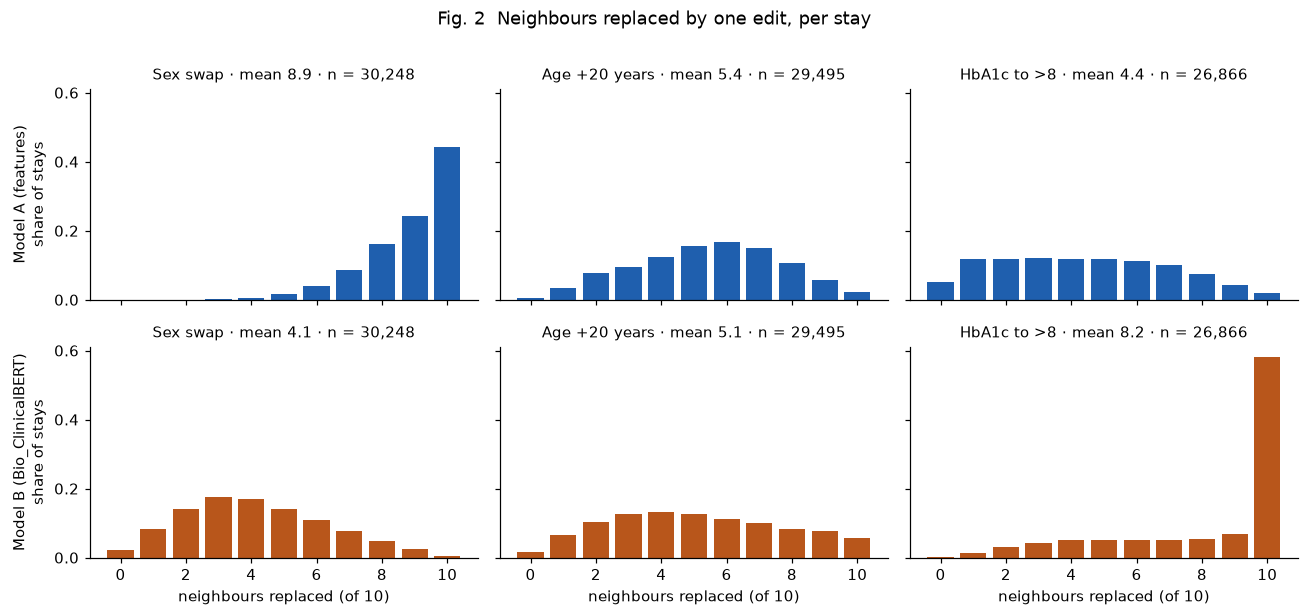

In [70]:
fig, axes = plt.subplots(2, 3, figsize=(12, 5.5), sharex=True, sharey=True)
split = {}
for i, m in enumerate(MODELS):
    for j, (e, label) in enumerate(EDITS.items()):
        s = df.loc[df[f"{e}_applied"], f"{m}_flips_{e}"].astype(int)
        axes[i, j].bar(range(11), s.value_counts(normalize=True).reindex(range(11), fill_value=0), color=COL[m])
        axes[i, j].set_title(f"{label} · mean {s.mean():.1f} · n = {len(s):,}", fontsize=10)
        split[(MODELS[m], label)] = {"≤ 3 replaced": (s <= 3).mean(), "≥ 9 replaced": (s >= 9).mean(), "mean": s.mean()}
    axes[i, 0].set_ylabel(MODELS[m] + "\nshare of stays")
for ax in axes[1]:
    ax.set_xlabel("neighbours replaced (of 10)")
fig.suptitle("Fig. 2  Neighbours replaced by one edit, per stay", y=1.01)
plt.tight_layout()
pd.DataFrame(split).T.round(3)

**Fig. 2.** The averages hide a split. Under the sex swap, Model A replaces 9 or 10 neighbours for 68.5% of stays and almost never keeps the neighbourhood stable (0.3% with ≤ 3). Under the HbA1c edit, Model B replaces 9 or 10 for 65.2% of stays, while 9% stay stable. Model B is mostly stable under the sex swap (42.3% with ≤ 3). The age edit spreads over the whole range for both models.

## 3. RQ4  Why fragile = neighbours change easily? Crowded neighbourhoods

Relative gap = (distance of neighbour 10 − distance of neighbour 1) / distance of neighbour 10. A small gap means the 10 neighbours are almost equally far away, so a small change can let other patients overtake them.

median distance to the 10th neighbour: {'Model A (features)': 0.11323, 'Model B (Bio_ClinicalBERT)': 0.0006}


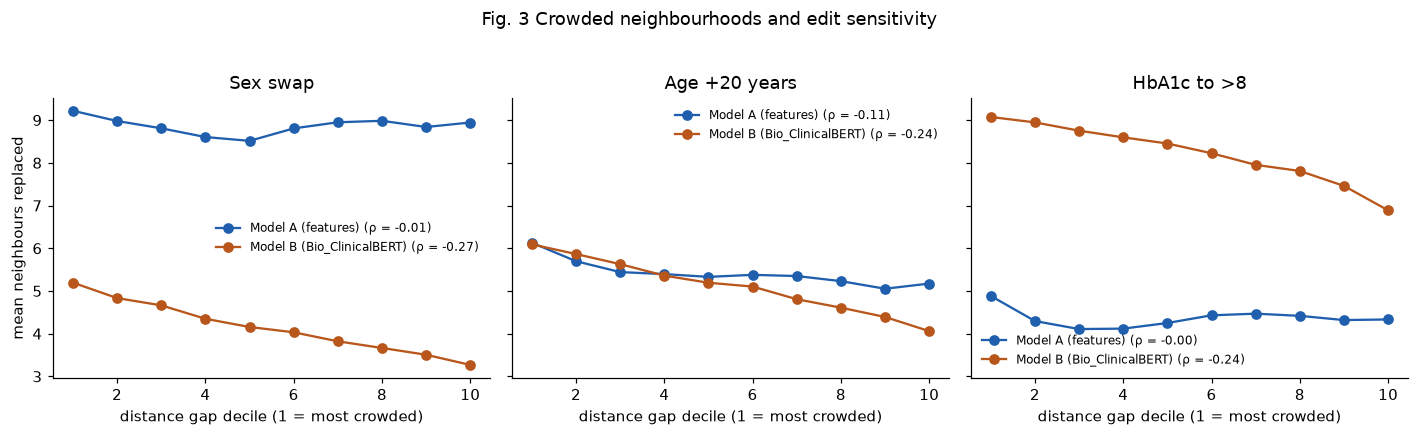

In [71]:
for m in MODELS:
    d = np.stack(df[f"{m}_distances"].to_numpy())
    df[f"{m}_d10"] = d[:, -1]
    df[f"{m}_rel_gap"] = (d[:, -1] - d[:, 0]) / d[:, -1]
print("median distance to the 10th neighbour:",
      {MODELS[m]: round(float(df[f"{m}_d10"].median()), 5) for m in MODELS})

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (e, label) in zip(axes, EDITS.items()):
    sub = df[df[f"{e}_applied"]]
    for m in MODELS:
        dec = pd.qcut(sub[f"{m}_rel_gap"], 10, labels=False, duplicates="drop")
        y = sub.groupby(dec)[f"{m}_flips_{e}"].mean()
        rho = sub[f"{m}_rel_gap"].corr(sub[f"{m}_flips_{e}"].astype(float), method="spearman")
        ax.plot(y.index + 1, y.values, "o-", color=COL[m], label=f"{MODELS[m]} (ρ = {rho:.2f})")
    ax.set_title(label)
    ax.set_xlabel("distance gap decile (1 = most crowded)")
    ax.legend(frameon=False, fontsize=8)
axes[0].set_ylabel("mean neighbours replaced")
fig.suptitle("Fig. 3 Crowded neighbourhoods and edit sensitivity", y=1.03)
plt.tight_layout()

**Fig. 3.** Model B's distances are tiny (median distance to the 10th neighbour about 0.0006, Model A about 0.11). For Model B, the more crowded the neighbourhood, the more neighbours an edit replaces: under the HbA1c edit from 9.1 in the most crowded to 6.9 in the least crowded, under the sex swap from 5.2 to 3.3. For Model A the lines are flat crowding does not explain its sensitivity. For Model B the gap is therefore a stability signal: a small gap warns that the neighbours would change with a small edit. For Model B it is not a confidence signal: its accuracy is about the same in every gap group (61–64%). For Model A, accuracy falls slightly from the most to the least crowded group (66% → 60%).


In [72]:
# does the gap relate to correctness? Accuracy per gap group (1 = most crowded)
pd.DataFrame({MODELS[m]: df[f"{m}_correct"].groupby(pd.qcut(df[f"{m}_rel_gap"], 10, labels=False, duplicates="drop") + 1).mean()
              for m in MODELS}).rename_axis("gap group").round(3).T

gap group,1,2,3,4,5,6,7,8,9,10
Model A (features),0.656,0.656,0.642,0.645,0.649,0.622,0.617,0.607,0.611,0.598
Model B (Bio_ClinicalBERT),0.639,0.617,0.633,0.629,0.613,0.635,0.625,0.644,0.623,0.638


## 4. RQ4 Who is fragile = neighbours change easily, and where?

Input feature UMAP (precomputed from the 15 input fields, no model internals)

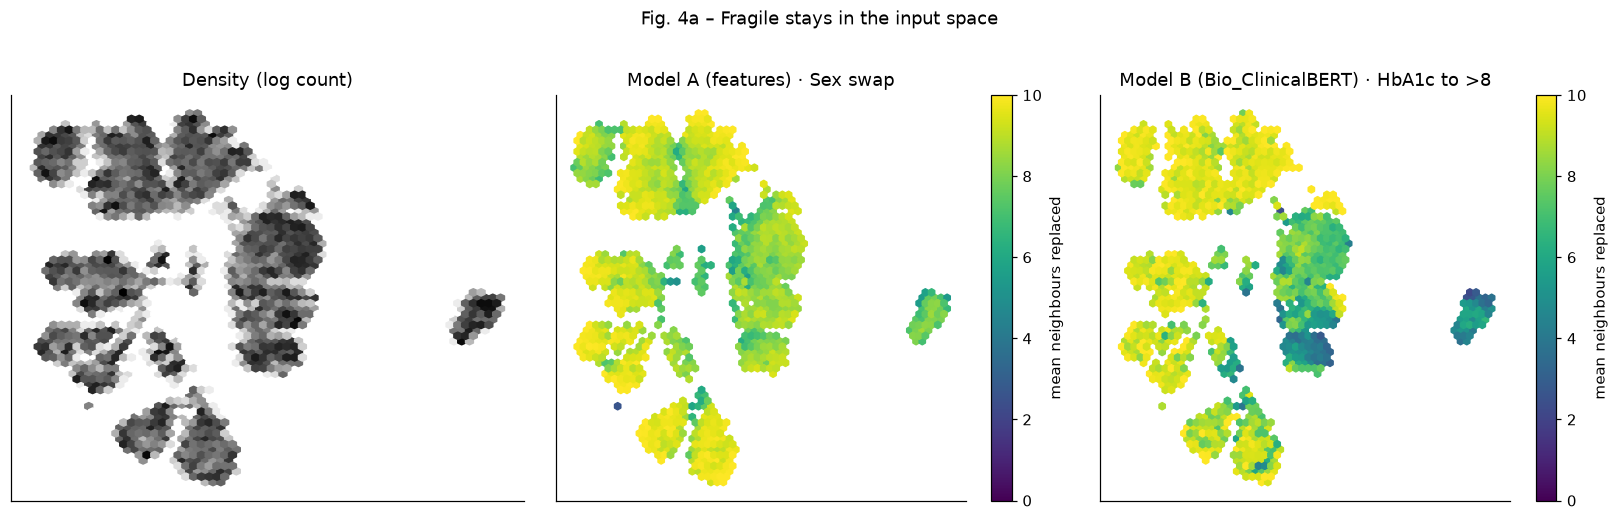

In [73]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6))
axes[0].hexbin(df.umap_x, df.umap_y, gridsize=60, bins="log", cmap="Greys")
axes[0].set_title("Density (log count)")
for ax, (m, e) in zip(axes[1:], [("model_a", "sex_swap"), ("model_b", "hba1c_elevation")]):
    sub = df[df[f"{e}_applied"]]
    hb = ax.hexbin(sub.umap_x, sub.umap_y, C=sub[f"{m}_flips_{e}"].astype(float), reduce_C_function=np.mean,
                   gridsize=60, cmap="viridis", vmin=0, vmax=10, mincnt=5)
    ax.set_title(f"{MODELS[m]} · {EDITS[e]}")
    fig.colorbar(hb, ax=ax, label="mean neighbours replaced")
for ax in axes:
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle("Fig. 4a – Fragile stays in the input space", y=1.02)
plt.tight_layout()

In [74]:
# What separates the regions of the UMAP? Mean horizontal position and Model B's HbA1c flips per admission source
sub = df[df["hba1c_elevation_applied"]]
(sub.groupby("admission_source")
    .agg(stays=("umap_x", "size"), mean_umap_x=("umap_x", "mean"),
         mean_B_hba1c_flips=("model_b_flips_hba1c_elevation", "mean"),
         mean_A_sex_flips=("model_a_flips_sex_swap", "mean"))
    .sort_values("stays", ascending=False).head(5).round(2))

,stays,mean_umap_x,mean_B_hba1c_flips,mean_A_sex_flips
admission_source,,,,
Emergency Room,16335,-0.92,9.33,9.28
Physician Referral,7359,3.42,7.02,8.54
NULL,1829,8.61,5.16,7.74
Transfer from a hospital,488,2.61,4.57,7.97
Transfer from another health care facility,370,0.04,6.62,7.97


**Fig. 4a.** For Model A, the sex swap replaces most neighbours almost everywhere in the input space; only the central island is somewhat less affected. For Model B, fragility follows the regions: the islands on the left are almost entirely fragile (about 10 replaced), the large central island is moderate (5–7) and the small island on the right is the most stable (about 4–5). The table shows what separates these regions: admission source. Emergency-room stays lie on the left (mean horizontal position −0.9) and lose 9.3 neighbours under the HbA1c edit; physician referrals lie in the centre (3.4) and lose 7.0; stays with a missing admission source form the island on the right (8.6) and lose 5.2.

Fragile (9–10 replaced) vs. stable (0–3 replaced) stays: the input fields that differ most, as standardized difference.

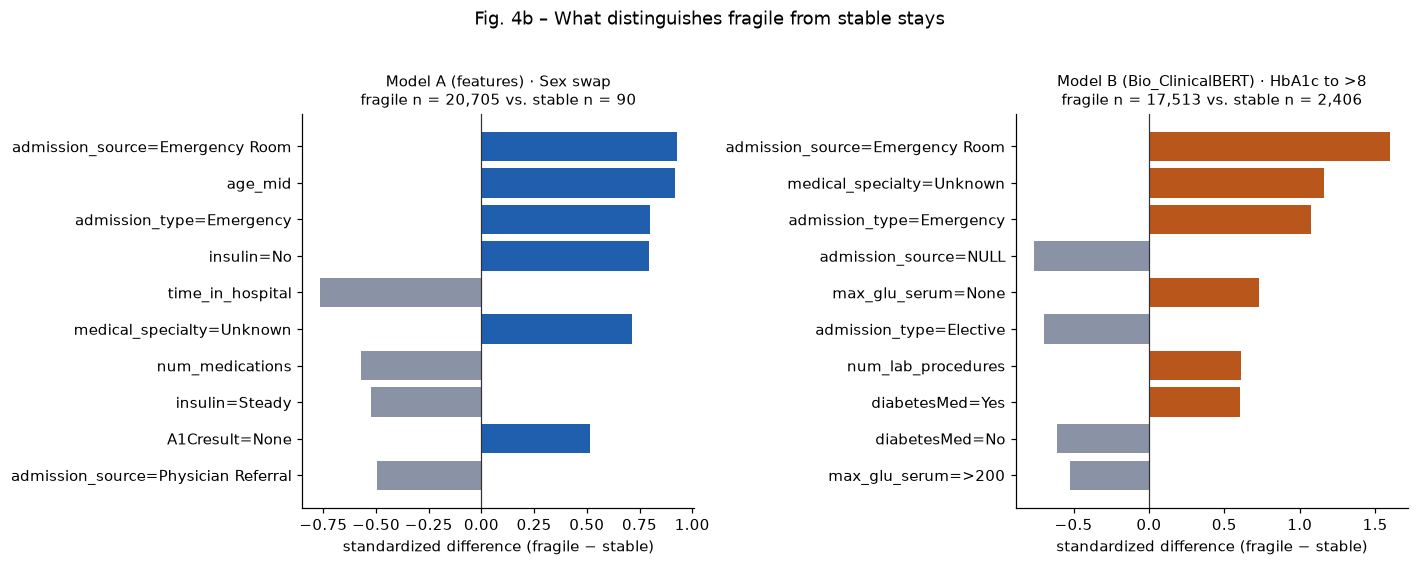

In [63]:
categorical = ["gender", "race", "admission_type", "admission_source", "medical_specialty", "payer_code",
               "max_glu_serum", "A1Cresult", "insulin", "change", "diabetesMed"]
X = pd.concat([df[numeric], pd.get_dummies(df[categorical], prefix_sep="=").astype(float)], axis=1)

def smd(a, b):
    sd = np.sqrt((X[a].var() + X[b].var()) / 2).replace(0, np.nan)
    return ((X[a].mean() - X[b].mean()) / sd).dropna()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (m, e) in zip(axes, [("model_a", "sex_swap"), ("model_b", "hba1c_elevation")]):
    ok = df[f"{e}_applied"]
    fragile, stable = ok & (df[f"{m}_flips_{e}"] >= 9), ok & (df[f"{m}_flips_{e}"] <= 3)
    s = smd(fragile, stable)
    top = s.reindex(s.abs().sort_values(ascending=False).index[:10])[::-1]
    ax.barh(top.index, top.values, color=np.where(top.values > 0, COL[m], COL["random"]))
    ax.axvline(0, color="#333", lw=0.8)
    ax.set_title(f"{MODELS[m]} · {EDITS[e]}\nfragile n = {fragile.sum():,} vs. stable n = {stable.sum():,}", fontsize=10)
    ax.set_xlabel("standardized difference (fragile − stable)")
fig.suptitle("Fig. 4b – What distinguishes fragile from stable stays", y=1.02)
plt.tight_layout()

In [64]:
# Model B: emergency admissions with unknown specialty
tab = (pd.DataFrame({"emergency_room": df["admission_source"].eq("Emergency Room"),
                     "unknown_specialty": df["medical_specialty"].eq("Unknown"),
                     "d10": df["model_b_d10"],
                     "hba1c_flips": df["model_b_flips_hba1c_elevation"].astype(float),
                     "correct": df["model_b_correct"]})
       .groupby(["emergency_room", "unknown_specialty"])
       .agg(stays=("d10", "size"), median_d10=("d10", "median"),
            mean_hba1c_flips=("hba1c_flips", "mean"), accuracy=("correct", "mean")))
tab.round(5)

stays  median_d10  mean_hba1c_flips  \
emergency_room unknown_specialty                                        
False          False               6858     0.00091           5.56004   
               True                4740     0.00067           7.84048   
True           False               7966     0.00061           8.64783   
               True               10684     0.00042           9.81814   

                                  accuracy  
emergency_room unknown_specialty            
False          False               0.65792  
               True                0.63523  
True           False               0.62240  
               True                0.61428

**Fig. 4b and table.** For Model B, fragile stays under the HbA1c edit are emergency admissions: 80% came via the emergency room (stable stays: 18%) and 66% have no recorded specialty (stable: 17%); stable stays are mostly elective. The table connects this with Fig. 3: the 10,684 stays that are both emergency and unknown specialty (35% of the cohort) have the most crowded neighbourhoods (median distance to the 10th neighbour 0.00042 vs. 0.00091 for elective stays with a known specialty) and lose 9.8 of 10 neighbours under the HbA1c edit (vs. 5.6). Their accuracy is also lowest (61.4% vs. 65.8%). For Model A, fragile stays under the sex swap are older (68 vs. 50 years) and more often emergency admissions -> *but only 90 stays are stable, so this comparison is weak*.

## 5. RQ4 Does it matter? Edits that change the prediction

,Model A (features),Model B (Bio_ClinicalBERT)
Sex swap,0.210,0.137
Age +20 years,0.171,0.164
HbA1c to >8,0.133,0.184


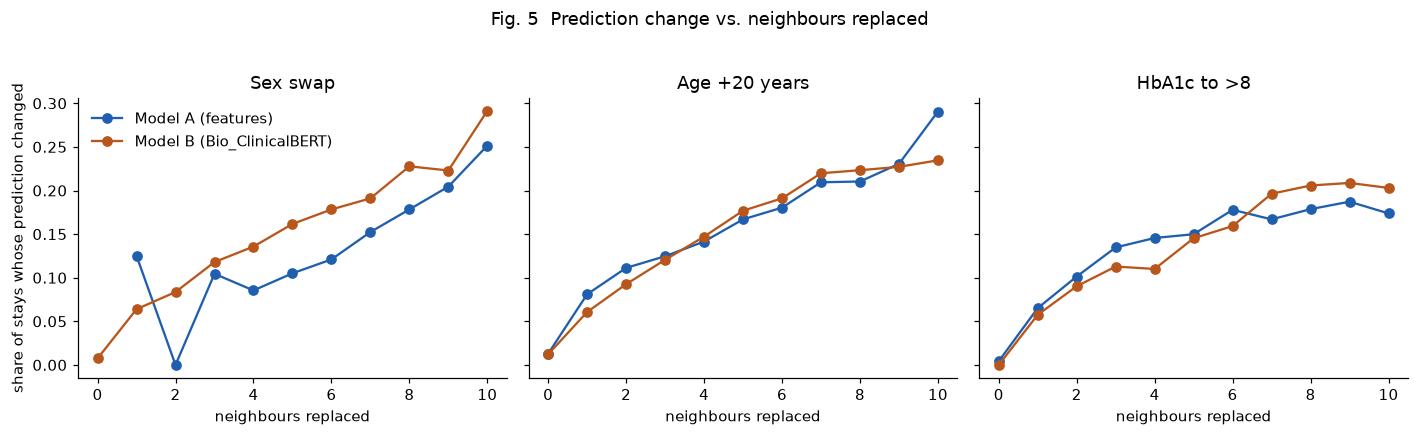

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (e, label) in zip(axes, EDITS.items()):
    sub = df[df[f"{e}_applied"]]
    for m in MODELS:
        y = sub.groupby(sub[f"{m}_flips_{e}"].astype(int))[f"{m}_pred_changed_{e}"].mean()
        ax.plot(y.index, y.values, "o-", color=COL[m], label=MODELS[m])
    ax.set_title(label)
    ax.set_xlabel("neighbours replaced")
axes[0].set_ylabel("share of stays whose prediction changed")
axes[0].legend(frameon=False)
fig.suptitle("Fig. 5  Prediction change vs. neighbours replaced", y=1.03)
plt.tight_layout()
pd.DataFrame({MODELS[m]: {label: df.loc[df[f"{e}_applied"], f"{m}_pred_changed_{e}"].mean()
                          for e, label in EDITS.items()} for m in MODELS}).round(3)

**Fig. 5.** Replaced neighbours change the prediction far less often than the flips suggest: the sex swap changes Model A's prediction for 21.0% of stays (Model B 13.7%), the HbA1c edit changes Model B's for 18.4% (Model A 13.3%). Even with all 10 neighbours replaced, most predictions stay the same, because most new neighbourhoods still vote "uncomplicated".

**Answer to RQ4.** Each model has one dominant edit -sex for Model A, HbA1c for Model B and the effect is split: for about two thirds of stays the whole neighbourhood is replaced, for a minority it stays stable (Fig. 2). For Model B the fragile stays are those with crowded neighbourhoods (Fig. 3), above all emergency admissions with unknown specialty (Fig. 4b). Model A's sensitivity to sex is not explained by crowding. The prediction changes for 13–21% of stays, much less than the neighbourhoods (Fig. 5).

## 6. RQ1 / RQ5 – Why are the rare pathways never predicted?

For every kidney and eye/neuro stay: how many of its 10 neighbours have the same next pathway, compared with random neighbours.

,model_a,model_b,random
Kidney / Renal,0.30,0.32,0.26
Eye / Neurological,0.42,0.35,0.17


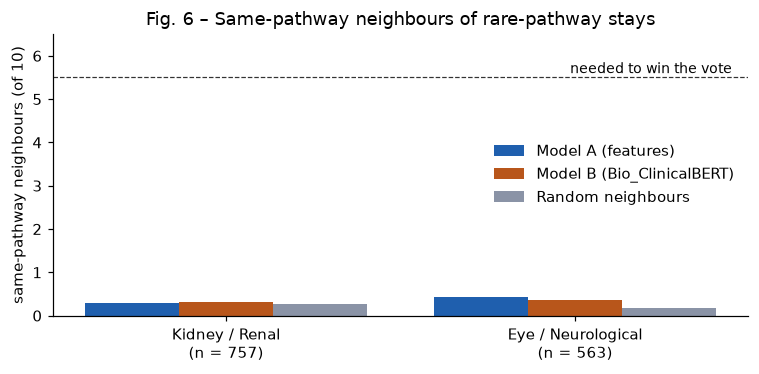

In [75]:
y_true = df["true_next_pathway"].to_numpy()
rare = {}
for p in ["Kidney / Renal", "Eye / Neurological"]:
    q = np.where(y_true == p)[0]
    rare[p] = {m: (y_true[NB[m][q]] == p).sum(axis=1).mean() for m in NB}
rare = pd.DataFrame(rare).T
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(rare))
for k, m in enumerate(["model_a", "model_b", "random"]):
    ax.bar(x + (k - 1) * 0.27, rare[m], width=0.27, color=COL[m], label={**MODELS, "random": "Random neighbours"}[m])
ax.set_xticks(x, [f"{p}\n(n = {(y_true == p).sum()})" for p in rare.index])
ax.set_ylabel("same-pathway neighbours (of 10)")
ax.axhline(5.5, color="#333", ls="--", lw=0.8)
ax.text(1.45, 5.6, "needed to win the vote", ha="right", fontsize=9)
ax.set_ylim(0, 6.5)
ax.legend(frameon=False)
ax.set_title("Fig. 6 – Same-pathway neighbours of rare-pathway stays")
plt.tight_layout()
rare.round(2)

In [76]:
# One example: the kidney stay for which Model B finds the most kidney neighbours
q = np.where(y_true == "Kidney / Renal")[0]
i = q[(y_true[NB["model_b"][q]] == "Kidney / Renal").sum(axis=1).argmax()]
pd.DataFrame({MODELS[m]: list(y_true[NB[m][i]]) + [df[f"{m}_pred_pathway"][i]] for m in MODELS},
             index=[f"neighbour {k}" for k in range(1, 11)] + ["prediction"]).rename_axis(f"stay {df.encounter_id[i]}")

,Model A (features),Model B (Bio_ClinicalBERT)
stay 262460496,,
neighbour 1,Uncomplicated / Other,Uncomplicated / Other
neighbour 2,Uncomplicated / Other,Kidney / Renal
neighbour 3,Uncomplicated / Other,Kidney / Renal
neighbour 4,Uncomplicated / Other,Uncomplicated / Other
neighbour 5,Uncomplicated / Other,Kidney / Renal
neighbour 6,Cardiovascular,Uncomplicated / Other
neighbour 7,Uncomplicated / Other,Uncomplicated / Other
neighbour 8,Uncomplicated / Other,Uncomplicated / Other
neighbour 9,Uncomplicated / Other,Cardiovascular


**Fig. 6.** Kidney stays get 0.30 (A) and 0.32 (B) kidney neighbours out of 10 – barely more than random neighbours (0.26). Eye/neuro stays get 0.42 same-pathway neighbours in Model A, more than twice the random level (0.17), Model B 0.35. Both models therefore carry some signal for the rare pathways, but far from the 6 neighbours a majority vote needs. Example: kidney stay 262460496 has 3 kidney neighbours in Model B and none in Model A; both still predict "uncomplicated".

**Answer to RQ1 / RQ5.** The rare pathways are not predicted because the 10-neighbour majority vote hides the signal, not because the neighbours never contain it: for eye/neuro, Model A finds same-pathway neighbours well above chance. For kidney, both models are close to random.

## 7. Output diversity – are a few patients retrieved for everyone?

In [77]:
occ = {m: np.bincount(NB[m].ravel(), minlength=len(df)) for m in NB}
pd.DataFrame({m: {"max retrievals": occ[m].max(),
                  "top 1% share of all slots": np.sort(occ[m])[::-1][: len(df) // 100].sum() / occ[m].sum(),
                  "never retrieved": (occ[m] == 0).mean()} for m in occ}).round(3)

,model_a,model_b,random
max retrievals,39.000,50.000,26.000
top 1% share of all slots,0.028,0.032,0.019
never retrieved,0.016,0.015,0.000


No strong hubs (hubs = patients who appear in the neighbour lists of very many other patients): the most retrieved stay appears 39 (A) or 50 (B) times against 26 for random neighbours, and the top 1% hold about 3% of all neighbour slots (random 1.9%). About 1.5% of stays are never retrieved by either model. Output diversity is therefore not a problem for either model (negative result).

## 8. Comparison with Pair A

| RQ | Pair A (AI-aided)  what happens, as averages | Pair B  why and for whom, per stay |
|---|---|---|
| RQ1 | Both models (63.0%) below the majority class (66.4%); rare pathways 0% recall | The vote hides the rare-pathway signal; for eye/neuro, A finds neighbours above chance (Fig. 6) |
| RQ2 | Only votes ≥ 8/10 beat the majority class | For Model B, crowded neighbourhoods signal unstable neighbours, not wrong answers (Fig. 3) |
| RQ3 | Race gap is a base-rate effect; 94.7% same sex in A | A matches on sex, B on administrative text; B weighs the numbers half as much (Fig. 1, 1b) |
| RQ4 | Mean neighbours replaced: sex 8.9 (A), HbA1c 8.2 (B) | Split into fragile and stable stays; B fragile where crowded – emergency stays with unknown specialty (Fig. 2–5) |

## 9. Conclusions

- **Same accuracy, different notions of similarity.** Model A's neighbours are patients of the same sex with similar numbers; Model B's are patients from the same department and admission route.
- **Model B is fragile where its text is generic.** Emergency stays with unknown specialty (a third of the cohort) sit in the most crowded neighbourhoods, and one changed token (HbA1c) replaces almost all 10 neighbours.
- **The majority vote hides signal.** Rare pathways appear among the neighbours, but never often enough to win.
- **Negative results:** no strong hubs (hubs = patients who appear in the neighbour lists of very many other patients) crowding does not explain Model A's sensitivity; no race preference in either model.

**Limitations.** All findings come from inputs and outputs only. The link between generic text and crowding is a hypothesis; testing it needs new edits (rewording or swapping the specialty) or Phase II. Model A's fragile/stable comparison rests on only 90 stable stays.

